In [1]:
# Fitness Membership Retention & Churn Prediction
# Initial Data Exploration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Python libraries imported successfully!")


Python libraries imported successfully!


In [2]:
# Step 2: Load and inspect the dataset
df = pd.read_csv("data/gym_churn_us.csv")
# Check number of rows and columns
print("Dataset shape:", df.shape)
# Display column names
print("\nColumn names:")
print(df.columns.tolist())
# Preview first five members
display(df.head())
# Check data types and missing values
print("\nDataset information:")
df.info()


Dataset shape: (4000, 14)

Column names:
['gender', 'Near_Location', 'Partner', 'Promo_friends', 'Phone', 'Contract_period', 'Group_visits', 'Age', 'Avg_additional_charges_total', 'Month_to_end_contract', 'Lifetime', 'Avg_class_frequency_total', 'Avg_class_frequency_current_month', 'Churn']


,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total         

In [3]:
# Step 3: Calculate membership retention metrics
total_members = len(df)
churned_members = (df["Churn"] == 1).sum()
retained_members = (df["Churn"] == 0).sum()
churn_rate = (churned_members / total_members) * 100
retention_rate = (retained_members / total_members) * 100
print("FITNESS MEMBERSHIP RETENTION SUMMARY")
print("------------------------------------")
print(f"Total Members: {total_members:,}")
print(f"Churned Members: {churned_members:,}")
print(f"Retained Members: {retained_members:,}")
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")


FITNESS MEMBERSHIP RETENTION SUMMARY
------------------------------------
Total Members: 4,000
Churned Members: 1,061
Retained Members: 2,939
Churn Rate: 26.52%
Retention Rate: 73.47%


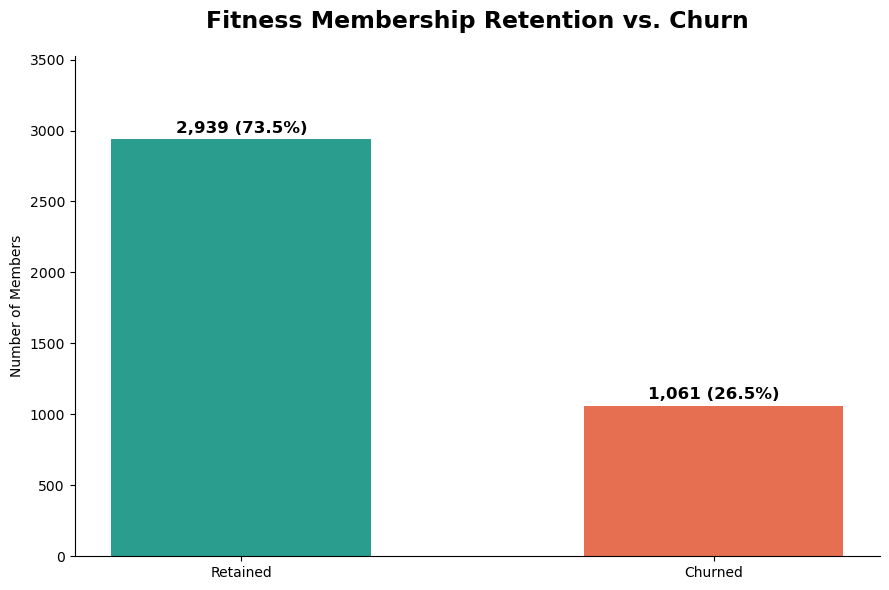

In [4]:
# Step 4: Visualize membership retention
import matplotlib.pyplot as plt
labels = ["Retained", "Churned"]
counts = [retained_members, churned_members]
colors = ["#2A9D8F", "#E76F51"]
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar(labels, counts, color=colors, width=0.55)
# Add member counts and percentages
for bar, count in zip(bars, counts):
    percentage = count / total_members * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 45,
        f"{count:,} ({percentage:.1f}%)",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_title(
    "Fitness Membership Retention vs. Churn",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Number of Members")
ax.set_ylim(0, max(counts) * 1.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
# Save chart to your figures folder
plt.savefig(
    "figures/membership_retention_overview.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Business Finding #1: Membership Retention
Of the 4,000 gym members analyzed, 1,061 (26.52%) were classified as churned, while 2,939 (73.48%) were retained.
This indicates that approximately one in four members in the dataset cancelled their memberships.
Understanding which membership characteristics and engagement behaviors are associated with churn could help fitness businesses identify at-risk customers and prioritize retention strategies.
*Next question:** How does workout attendance differ between members who stayed and members who cancelled?


AVERAGE WEEKLY GYM ATTENDANCE


,Avg_class_frequency_total,Avg_class_frequency_current_month
Retained,2.02,2.03
Churned,1.47,1.04


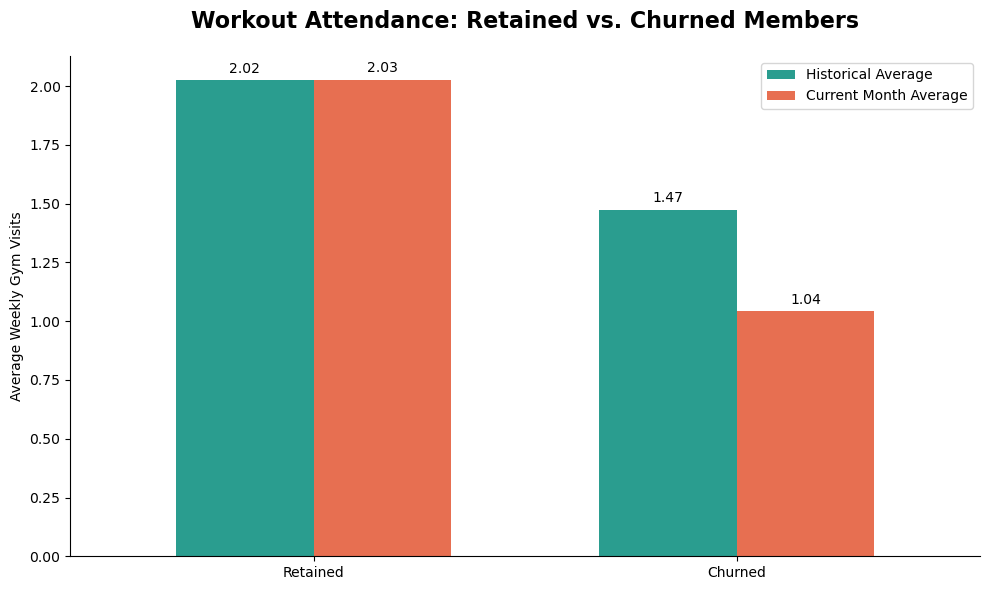

In [5]:
# Step 5: Analyze workout attendance and churn
attendance = df.groupby("Churn")[
    ["Avg_class_frequency_total",
     "Avg_class_frequency_current_month"]
].mean()
attendance.index = ["Retained", "Churned"]
print("AVERAGE WEEKLY GYM ATTENDANCE")
display(attendance.round(2))
# Create visualization
fig, ax = plt.subplots(figsize=(10, 6))
attendance.plot(
    kind="bar",
    ax=ax,
    color=["#2A9D8F", "#E76F51"],
    width=0.65
)
ax.set_title(
    "Workout Attendance: Retained vs. Churned Members",
    fontsize=16,
    fontweight="bold",
    pad=20
)
ax.set_ylabel("Average Weekly Gym Visits")
ax.set_xlabel("")
ax.set_xticklabels(attendance.index, rotation=0)
ax.legend([
    "Historical Average",
    "Current Month Average"
])
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "figures/attendance_vs_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Business Finding #2: Workout Engagement and Customer Churn
Members who cancelled their memberships demonstrated lower workout engagement than retained members.
Retained members averaged 2.02 weekly visits historically and 2.03 visits during the current month, indicating relatively stable engagement.
Churned members averaged 1.47 weekly visits historically, declining to 1.04 visits during the current month. This represents an approximate 29% reduction in attendance.
**Business implication:** Fitness subscription companies could investigate declining engagement as a potential indicator of cancellation risk. Tracking changes in activity may help identify customers who could benefit from personalized outreach, engagement incentives, or retention initiatives.
These findings demonstrate an association rather than causation. Additional analysis would be required to establish whether attendance declines occur before cancellation.

CHURN RATE BY CONTRACT LENGTH


,Contract_period,Total_Members,Churned_Members,Churn_Rate
0,1,2207,934,42.32
1,6,833,104,12.48
2,12,960,23,2.40


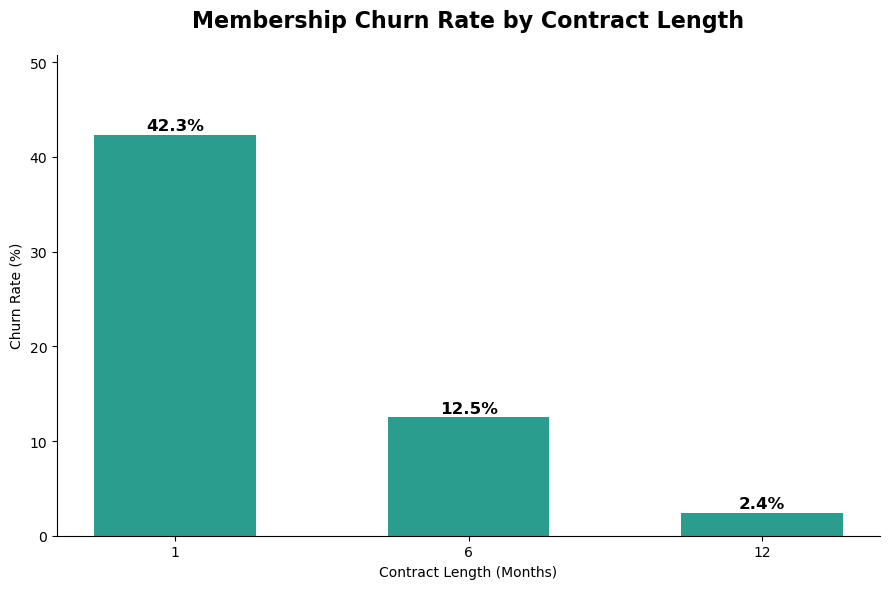

In [6]:
# Step 6: Analyze contract length and churn
contract_analysis = df.groupby("Contract_period").agg(
    Total_Members=("Churn", "count"),
    Churned_Members=("Churn", "sum"),
    Churn_Rate=("Churn", "mean")
).reset_index()
contract_analysis["Churn_Rate"] *= 100
print("CHURN RATE BY CONTRACT LENGTH")
display(contract_analysis.round(2))
# Visualization
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar(
    contract_analysis["Contract_period"].astype(str),
    contract_analysis["Churn_Rate"],
    color="#2A9D8F",
    width=0.55
)
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.1f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )
ax.set_title(
    "Membership Churn Rate by Contract Length",
    fontsize=16,
    fontweight="bold",
    pad=20
)
ax.set_xlabel("Contract Length (Months)")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, max(contract_analysis["Churn_Rate"]) * 1.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "figures/churn_by_contract_length.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Business Finding #3: Contract Length and Customer Retention
Membership contract length demonstrated a strong association with customer churn.
Members with one-month contracts experienced a 42.32% churn rate, compared with 12.48% for six-month contracts and 2.40% for twelve-month contracts.
This suggests that customers on shorter contracts represent a potentially higher-risk retention segment.
**Business implication:** Fitness subscription companies could prioritize engagement initiatives for month-to-month customers, test incentives for longer commitments, and investigate whether contract flexibility influences retention.
These results are observational and do not establish that longer contracts directly reduce cancellation risk. Contract terms may also affect when customers are able to cancel.

CORRELATION WITH CUSTOMER CHURN


Lifetime                            -0.438
Avg_class_frequency_current_month   -0.412
Age                                 -0.405
Contract_period                     -0.390
Month_to_end_contract               -0.381
Avg_class_frequency_total           -0.250
Avg_additional_charges_total        -0.199
Group_visits                        -0.175
Promo_friends                       -0.162
Partner                             -0.158
Near_Location                       -0.128
Phone                               -0.001
gender                               0.001
Name: Churn, dtype: float64

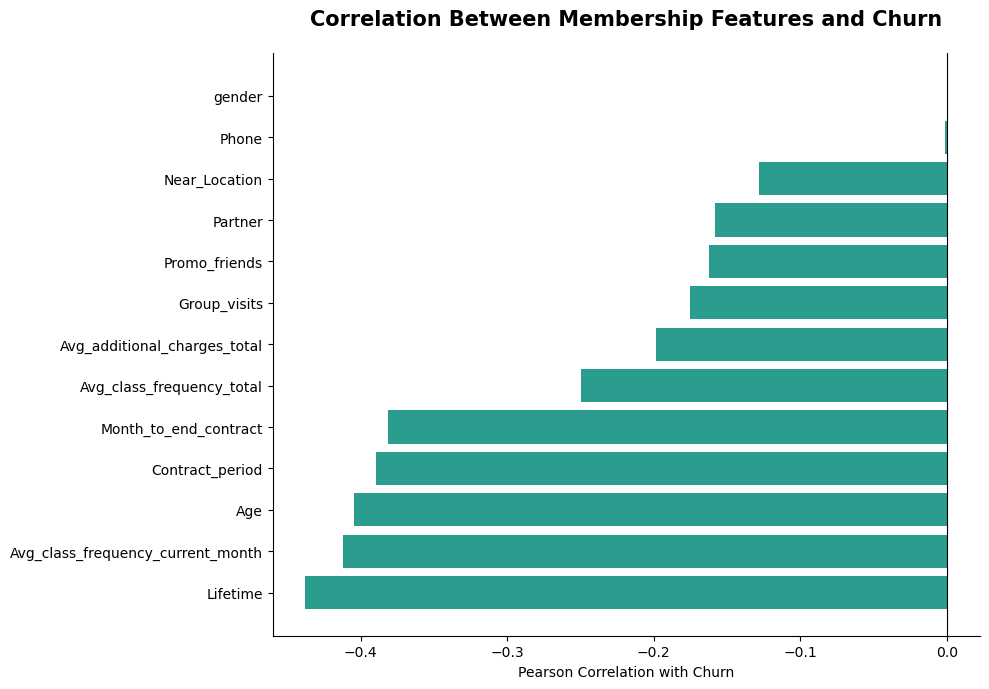

In [7]:
# Step 7: Explore correlations with churn
correlations = (
    df.corr(numeric_only=True)["Churn"]
    .drop("Churn")
    .sort_values()
)
print("CORRELATION WITH CUSTOMER CHURN")
display(correlations.round(3))
# Visualization
fig, ax = plt.subplots(figsize=(10, 7))
colors = [
    "#E76F51" if value > 0 else "#2A9D8F"
    for value in correlations.values
]
bars = ax.barh(
    correlations.index,
    correlations.values,
    color=colors
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(
    "Correlation Between Membership Features and Churn",
    fontsize=15,
    fontweight="bold",
    pad=20
)
ax.set_xlabel("Pearson Correlation with Churn")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(
    "figures/churn_feature_correlations.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [8]:
# Step 8: Build a baseline churn prediction model
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
# Use a conservative starting set of features
# Exclude lifetime, contract expiration, and
# current-month attendance pending timing checks.
features = [
    "gender",
    "Near_Location",
    "Partner",
    "Promo_friends",
    "Phone",
    "Contract_period",
    "Group_visits",
    "Age",
    "Avg_additional_charges_total",
    "Avg_class_frequency_total"
]
X = df[features]
y = df["Churn"]
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
# Build preprocessing and prediction pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=10000))
])
# Train model
model.fit(X_train, y_train)
# Make predictions
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]
# Evaluate performance
print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print(f"Accuracy:  {accuracy_score(y_test, predictions):.3f}")
print(f"Precision: {precision_score(y_test, predictions):.3f}")
print(f"Recall:    {recall_score(y_test, predictions):.3f}")
print(f"F1 Score:  {f1_score(y_test, predictions):.3f}")
print(f"ROC AUC:   {roc_auc_score(y_test, probabilities):.3f}")


LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy:  0.839
Precision: 0.761
Recall:    0.571
F1 Score:  0.652
ROC AUC:   0.893


In [9]:
# Step 9: Train and evaluate a Random Forest model
from sklearn.ensemble import RandomForestClassifier
# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
# Train on the same training data
rf_model.fit(X_train, y_train)
# Generate predictions
rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]
# Compare model performance
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],
    "Logistic Regression": [
        accuracy_score(y_test, predictions),
        precision_score(y_test, predictions),
        recall_score(y_test, predictions),
        f1_score(y_test, predictions),
        roc_auc_score(y_test, probabilities)
    ],
    "Random Forest": [
        accuracy_score(y_test, rf_predictions),
        precision_score(y_test, rf_predictions),
        recall_score(y_test, rf_predictions),
        f1_score(y_test, rf_predictions),
        roc_auc_score(y_test, rf_probabilities)
    ]
})
print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(3))


MODEL PERFORMANCE COMPARISON


,Metric,Logistic Regression,Random Forest
0,Accuracy,0.839,0.838
1,Precision,0.761,0.773
2,Recall,0.571,0.547
3,F1 Score,0.652,0.641
4,ROC AUC,0.893,0.888


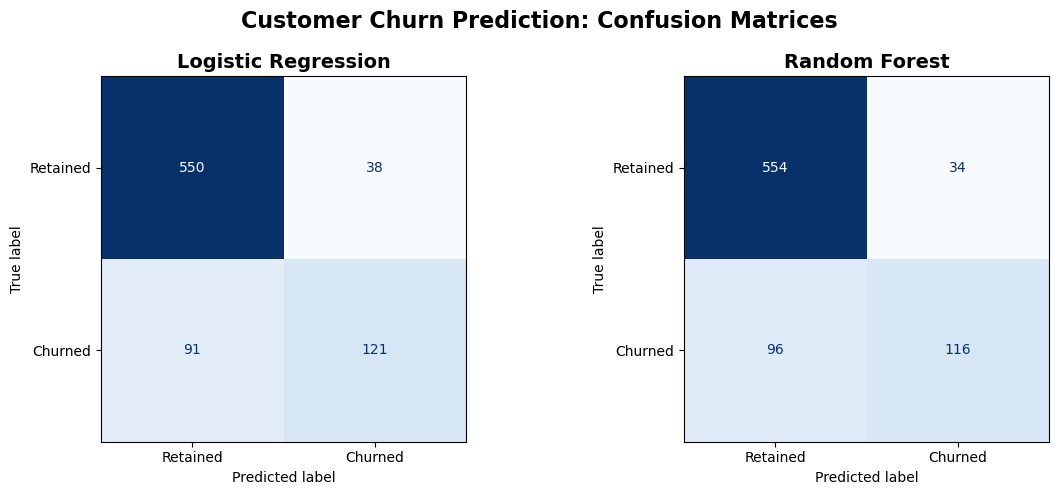

In [10]:
# Step 10: Compare confusion matrices
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
models = [
    ("Logistic Regression", predictions),
    ("Random Forest", rf_predictions)
]
for ax, (name, preds) in zip(axes, models):
    cm = confusion_matrix(y_test, preds)
    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Retained", "Churned"]
    )
    display_cm.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )
    ax.set_title(name, fontsize=14, fontweight="bold")
plt.suptitle(
    "Customer Churn Prediction: Confusion Matrices",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.savefig(
    "figures/model_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


CLASSIFICATION THRESHOLD COMPARISON


,Threshold,Precision,Recall,F1 Score,Flagged Members,Missed Cancellations
0,0.2,0.553,0.835,0.665,320,35
1,0.3,0.643,0.797,0.712,263,43
2,0.4,0.709,0.679,0.694,203,68
3,0.5,0.761,0.571,0.652,159,91
4,0.6,0.812,0.429,0.562,112,121


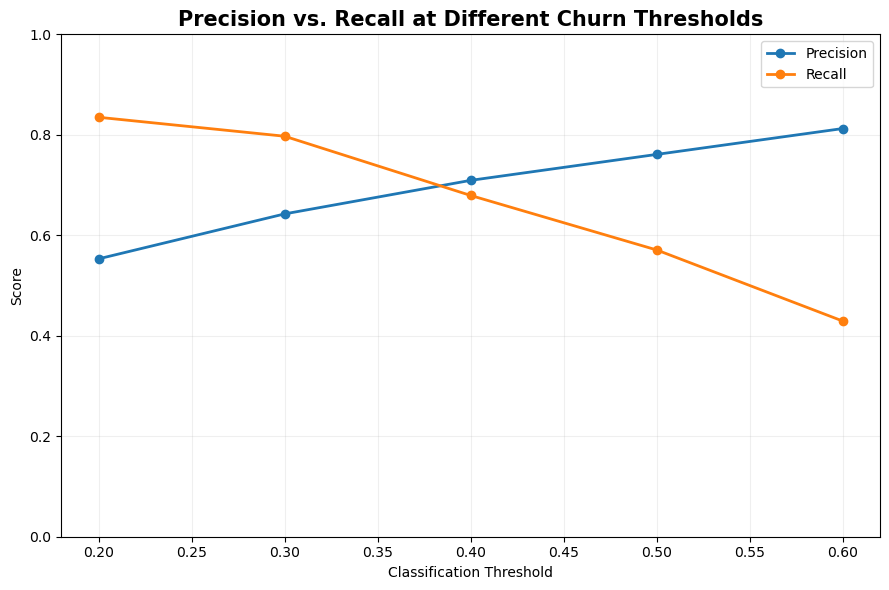

In [11]:
# Step 11: Evaluate different classification thresholds
threshold_results = []
for threshold in [0.20, 0.30, 0.40, 0.50, 0.60]:
    adjusted_predictions = (
        probabilities >= threshold
    ).astype(int)
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, adjusted_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, adjusted_predictions
        ),
        "F1 Score": f1_score(
            y_test, adjusted_predictions
        ),
        "Flagged Members": adjusted_predictions.sum(),
        "Missed Cancellations": (
            (y_test == 1) &
            (adjusted_predictions == 0)
        ).sum()
    })
threshold_df = pd.DataFrame(threshold_results)
print("CLASSIFICATION THRESHOLD COMPARISON")
display(threshold_df.round(3))
# Plot precision and recall
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    linewidth=2,
    label="Precision"
)
ax.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    linewidth=2,
    label="Recall"
)
ax.set_title(
    "Precision vs. Recall at Different Churn Thresholds",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    "figures/precision_recall_thresholds.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


LOGISTIC REGRESSION FEATURE COEFFICIENTS


,Feature,Coefficient
5,Contract_period,-1.361
7,Age,-1.165
9,Avg_class_frequency_total,-0.681
8,Avg_additional_charges_total,-0.517
6,Group_visits,-0.279
3,Promo_friends,-0.154
1,Near_Location,-0.111
2,Partner,-0.053
4,Phone,-0.052
0,gender,0.014


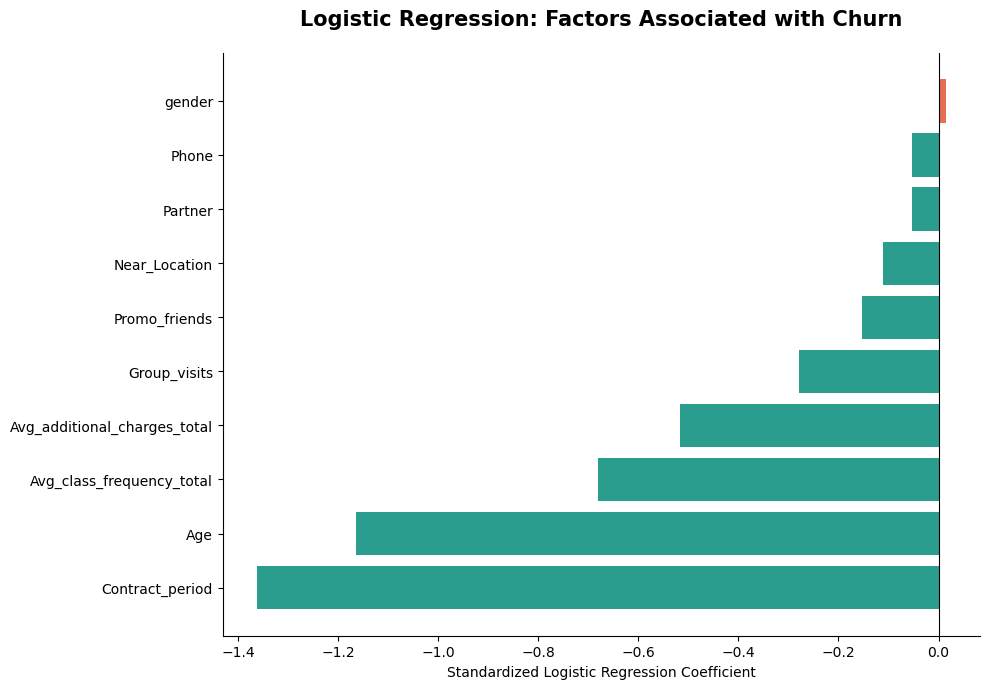

In [12]:
# Step 12: Logistic Regression Feature Coefficients
# Extract coefficients from trained model
coefficients = model.named_steps[
    "classifier"
].coef_[0]
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients
}).sort_values("Coefficient")
print("LOGISTIC REGRESSION FEATURE COEFFICIENTS")
display(feature_importance.round(3))
# Create visualization
fig, ax = plt.subplots(figsize=(10, 7))
colors = [
    "#E76F51" if coef > 0 else "#2A9D8F"
    for coef in feature_importance["Coefficient"]
]
ax.barh(
    feature_importance["Feature"],
    feature_importance["Coefficient"],
    color=colors
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(
    "Logistic Regression: Factors Associated with Churn",
    fontsize=15,
    fontweight="bold",
    pad=20
)
ax.set_xlabel("Standardized Logistic Regression Coefficient")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(
    "figures/logistic_regression_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Business Finding #6: Key Factors Associated with Customer Churn
Logistic regression analysis identified contract length, age, historical workout attendance, additional spending, and group class participation as the strongest predictors by absolute standardized coefficient magnitude.
Contract length had the largest coefficient (-1.361), followed by age (-1.165) and historical workout attendance (-0.681).
These findings suggest that membership commitment and engagement are important characteristics associated with customer retention.
**Business implication:** Fitness subscription companies could investigate retention strategies focused on shorter-contract members and customers with lower engagement. Potential interventions include personalized workout recommendations, class incentives, and targeted membership offers.
The coefficients represent statistical associations within the model rather than evidence that changing these factors would directly reduce churn.

In [13]:
# Step 13: Simulate a targeted retention campaign
# Create customer-level prediction results
campaign_df = pd.DataFrame({
    "Actual_Churn": y_test.to_numpy(),
    "Predicted_Churn_Probability": probabilities
})
# Rank customers from highest to lowest churn risk
campaign_df = campaign_df.sort_values(
    "Predicted_Churn_Probability",
    ascending=False
).reset_index(drop=True)
# Simulate outreach to the 100 highest-risk customers
campaign_size = 100
targeted_customers = campaign_df.head(campaign_size)
# Calculate campaign targeting metrics
actual_churners_targeted = int(
    targeted_customers["Actual_Churn"].sum()
)
total_churners = int(campaign_df["Actual_Churn"].sum())
targeting_precision = (
    actual_churners_targeted / campaign_size
)
churn_coverage = (
    actual_churners_targeted / total_churners
)
baseline_churn_rate = campaign_df["Actual_Churn"].mean()
lift = targeting_precision / baseline_churn_rate
print("TARGETED RETENTION CAMPAIGN SIMULATION")
print("--------------------------------------")
print(f"Customers evaluated: {len(campaign_df)}")
print(f"Customers targeted: {campaign_size}")
print(f"Actual churners in target group: {actual_churners_targeted}")
print(f"Targeting precision: {targeting_precision:.1%}")
print(f"Churn coverage: {churn_coverage:.1%}")
print(f"Overall churn rate: {baseline_churn_rate:.1%}")
print(f"Targeting lift: {lift:.2f}x")


TARGETED RETENTION CAMPAIGN SIMULATION
--------------------------------------
Customers evaluated: 800
Customers targeted: 100
Actual churners in target group: 83
Targeting precision: 83.0%
Churn coverage: 39.2%
Overall churn rate: 26.5%
Targeting lift: 3.13x


In [14]:
# Step 14: Hypothetical retention campaign ROI
# Assumptions (not observed in the dataset)
monthly_membership_revenue = 50
months_retained_per_save = 3
outreach_cost_per_customer = 5
campaign_success_rate = 0.10
# Results from Step 13
customers_contacted = campaign_size
at_risk_customers = actual_churners_targeted
# Estimated campaign outcomes
expected_customers_saved = (
    at_risk_customers * campaign_success_rate
)
revenue_per_saved_customer = (
    monthly_membership_revenue
    * months_retained_per_save
)
expected_revenue = (
    expected_customers_saved
    * revenue_per_saved_customer
)
campaign_cost = (
    customers_contacted
    * outreach_cost_per_customer
)
net_value = expected_revenue - campaign_cost
roi = (net_value / campaign_cost) * 100
print("HYPOTHETICAL RETENTION CAMPAIGN ROI")
print("-----------------------------------")
print(f"Customers contacted: {customers_contacted}")
print(f"At-risk customers targeted: {at_risk_customers}")
print(f"Expected customers saved: {expected_customers_saved:.1f}")
print(f"Expected additional revenue: ${expected_revenue:,.2f}")
print(f"Campaign cost: ${campaign_cost:,.2f}")
print(f"Estimated net value: ${net_value:,.2f}")
print(f"Estimated ROI: {roi:.1f}%")


HYPOTHETICAL RETENTION CAMPAIGN ROI
-----------------------------------
Customers contacted: 100
At-risk customers targeted: 83
Expected customers saved: 8.3
Expected additional revenue: $1,245.00
Campaign cost: $500.00
Estimated net value: $745.00
Estimated ROI: 149.0%


RETENTION CAMPAIGN SENSITIVITY ANALYSIS


,Success Rate,Expected Saves,Revenue,Campaign Cost,Net Value,ROI (%)
0,0.02,1.66,249.0,500,-251.0,-50.2
1,0.05,4.15,622.5,500,122.5,24.5
2,0.10,8.30,1245.0,500,745.0,149.0
3,0.15,12.45,1867.5,500,1367.5,273.5
4,0.20,16.60,2490.0,500,1990.0,398.0


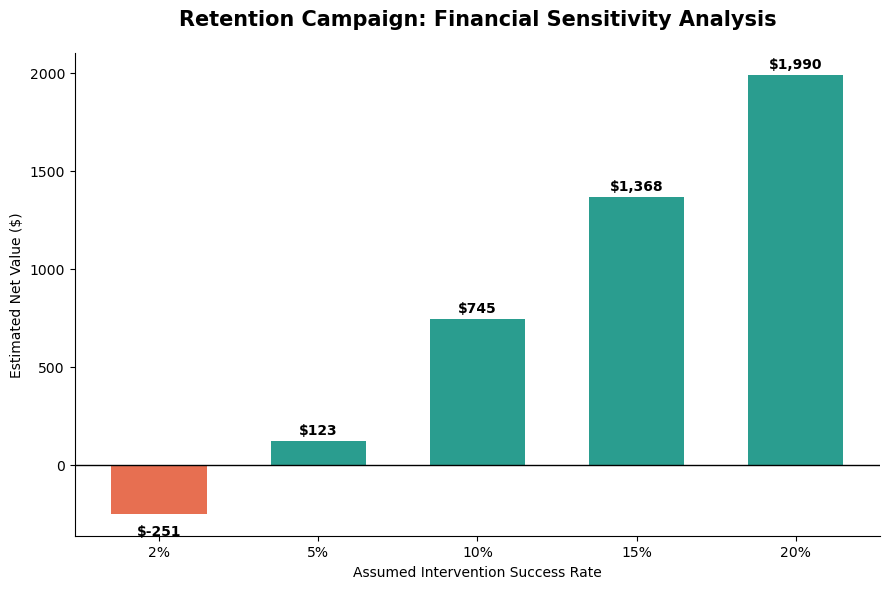


Break-even success rate: 4.02%


In [15]:
# Step 15: Retention campaign sensitivity analysis
success_rates = [0.02, 0.05, 0.10, 0.15, 0.20]
scenario_results = []
for rate in success_rates:
    customers_saved = at_risk_customers * rate
    revenue = (
        customers_saved
        * monthly_membership_revenue
        * months_retained_per_save
    )
    net = revenue - campaign_cost
    scenario_roi = (net / campaign_cost) * 100
    scenario_results.append({
        "Success Rate": rate,
        "Expected Saves": customers_saved,
        "Revenue": revenue,
        "Campaign Cost": campaign_cost,
        "Net Value": net,
        "ROI (%)": scenario_roi
    })
sensitivity_df = pd.DataFrame(scenario_results)
print("RETENTION CAMPAIGN SENSITIVITY ANALYSIS")
display(sensitivity_df.round(2))
# Plot net value across scenarios
fig, ax = plt.subplots(figsize=(9, 6))
colors = [
    "#2A9D8F" if value >= 0 else "#E76F51"
    for value in sensitivity_df["Net Value"]
]
bars = ax.bar(
    [f"{rate:.0%}" for rate in success_rates],
    sensitivity_df["Net Value"],
    color=colors,
    width=0.6
)
ax.axhline(0, color="black", linewidth=1)
for bar in bars:
    value = bar.get_height()
    ax.annotate(
        f"${value:,.0f}",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 5 if value >= 0 else -15),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )
ax.set_title(
    "Retention Campaign: Financial Sensitivity Analysis",
    fontsize=15,
    fontweight="bold",
    pad=20
)
ax.set_xlabel("Assumed Intervention Success Rate")
ax.set_ylabel("Estimated Net Value ($)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(
    "figures/retention_roi_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
# Calculate break-even intervention success rate
break_even_rate = campaign_cost / (
    at_risk_customers
    * monthly_membership_revenue
    * months_retained_per_save
)
print(f"\nBreak-even success rate: {break_even_rate:.2%}")


### Business Finding #8: Financial Sensitivity and Retention Strategy
The hypothetical retention campaign demonstrated how targeted customer outreach could generate financial value under different intervention effectiveness assumptions.
Using a campaign targeting 100 members, with 83 observed churners in the targeted group, the analysis assumed $50 in monthly membership revenue, three additional months of retention per successful intervention, and $5 in outreach costs per customer.
At a 10% intervention success rate, the campaign generated an estimated $1,245 in additional revenue and $745 in net value, representing a 149% revenue-based ROI.
Sensitivity analysis showed that the campaign would break even at approximately a 4.02% intervention success rate. Below this level, the campaign would lose money under the modeled assumptions.
**Business recommendation:** Fitness subscription companies could use predictive analytics to prioritize high-risk customers for targeted retention programs. However, actual financial benefits would need to be established through controlled intervention testing.
**Limitations:** The financial results are hypothetical and do not include membership servicing costs, discounts, or other operational expenses. The dataset does not establish the effectiveness of retention interventions, and the predictive model has not been prospectively validated.